# Confirmación pareada: selección de puntos de colocación

Burgers, 10 semillas. Todos los métodos comparten por semilla el calentamiento uniforme, los pesos y estado de Adam resultantes, los lotes supervisados, el conjunto candidato y el presupuesto de puntos. Se compara calidad al mismo número de pasos y tiempo observado hasta un objetivo de validación fijado antes de correr.

El objetivo es RMSE de validación ≤ 0.35; se registra el primer checkpoint observado que lo alcanza, sin interpolar. Las semillas que no llegan dentro del presupuesto quedan censuradas.

## Resumen por semilla

| Método | L2 relativo prueba (media ± DE) | Residuo independiente | Pipeline (s) |
|---|---:|---:|---:|
| Aleatorio uniforme | 0.5500 ± 0.0232 | 0.2158 ± 0.0212 | 1.5407 ± 0.8639 |
| Sobol | 0.5566 ± 0.0150 | 0.2001 ± 0.0084 | 1.4509 ± 0.6869 |
| RAD | 0.6028 ± 0.0138 | 0.1983 ± 0.0223 | 1.4452 ± 0.6816 |
| POD + QR | 0.5626 ± 0.0136 | 0.1931 ± 0.0063 | 1.4567 ± 0.6377 |
| PCA centrado + media + QR | 0.5629 ± 0.0124 | 0.1933 ± 0.0067 | 1.4633 ± 0.6165 |

Diferencias pareadas contra uniforme, promedio entre semillas:

| Método | Δ L2 relativo | Semillas con menor L2 | Δ residuo independiente | Semillas con menor residuo |
|---|---:|---:|---:|---:|
| Sobol | 0.0067 ± 0.0158 | 4/10 | -0.0157 ± 0.0180 | 8/10 |
| RAD | 0.0529 ± 0.0213 | 0/10 | -0.0174 ± 0.0322 | 8/10 |
| POD + QR | 0.0127 ± 0.0148 | 1/10 | -0.0226 ± 0.0177 | 9/10 |
| PCA centrado + media + QR | 0.0130 ± 0.0175 | 1/10 | -0.0224 ± 0.0193 | 9/10 |

## Objetivo de calidad equivalente

| Método | Alcanzan el objetivo | Tiempo medio entre aciertos (s) | Censuradas |
|---|---:|---:|---:|
| Aleatorio uniforme | 7/10 | 1.394 ± 0.636 | 3 |
| Sobol | 7/10 | 1.381 ± 0.640 | 3 |
| RAD | 3/10 | 1.705 ± 0.975 | 7 |
| POD + QR | 6/10 | 1.416 ± 0.700 | 4 |
| PCA centrado + media + QR | 5/10 | 1.432 ± 0.782 | 5 |

Los tiempos incluyen el calentamiento y preparación compartidos, una vez por corrida. Los promedios de tiempo entre aciertos son descriptivos y no ordenan por sí solos a los métodos: deben leerse junto con la tasa de aciertos y las semillas censuradas.

## Diagnósticos visuales

**Calidad en el conjunto de prueba y residuo independiente**

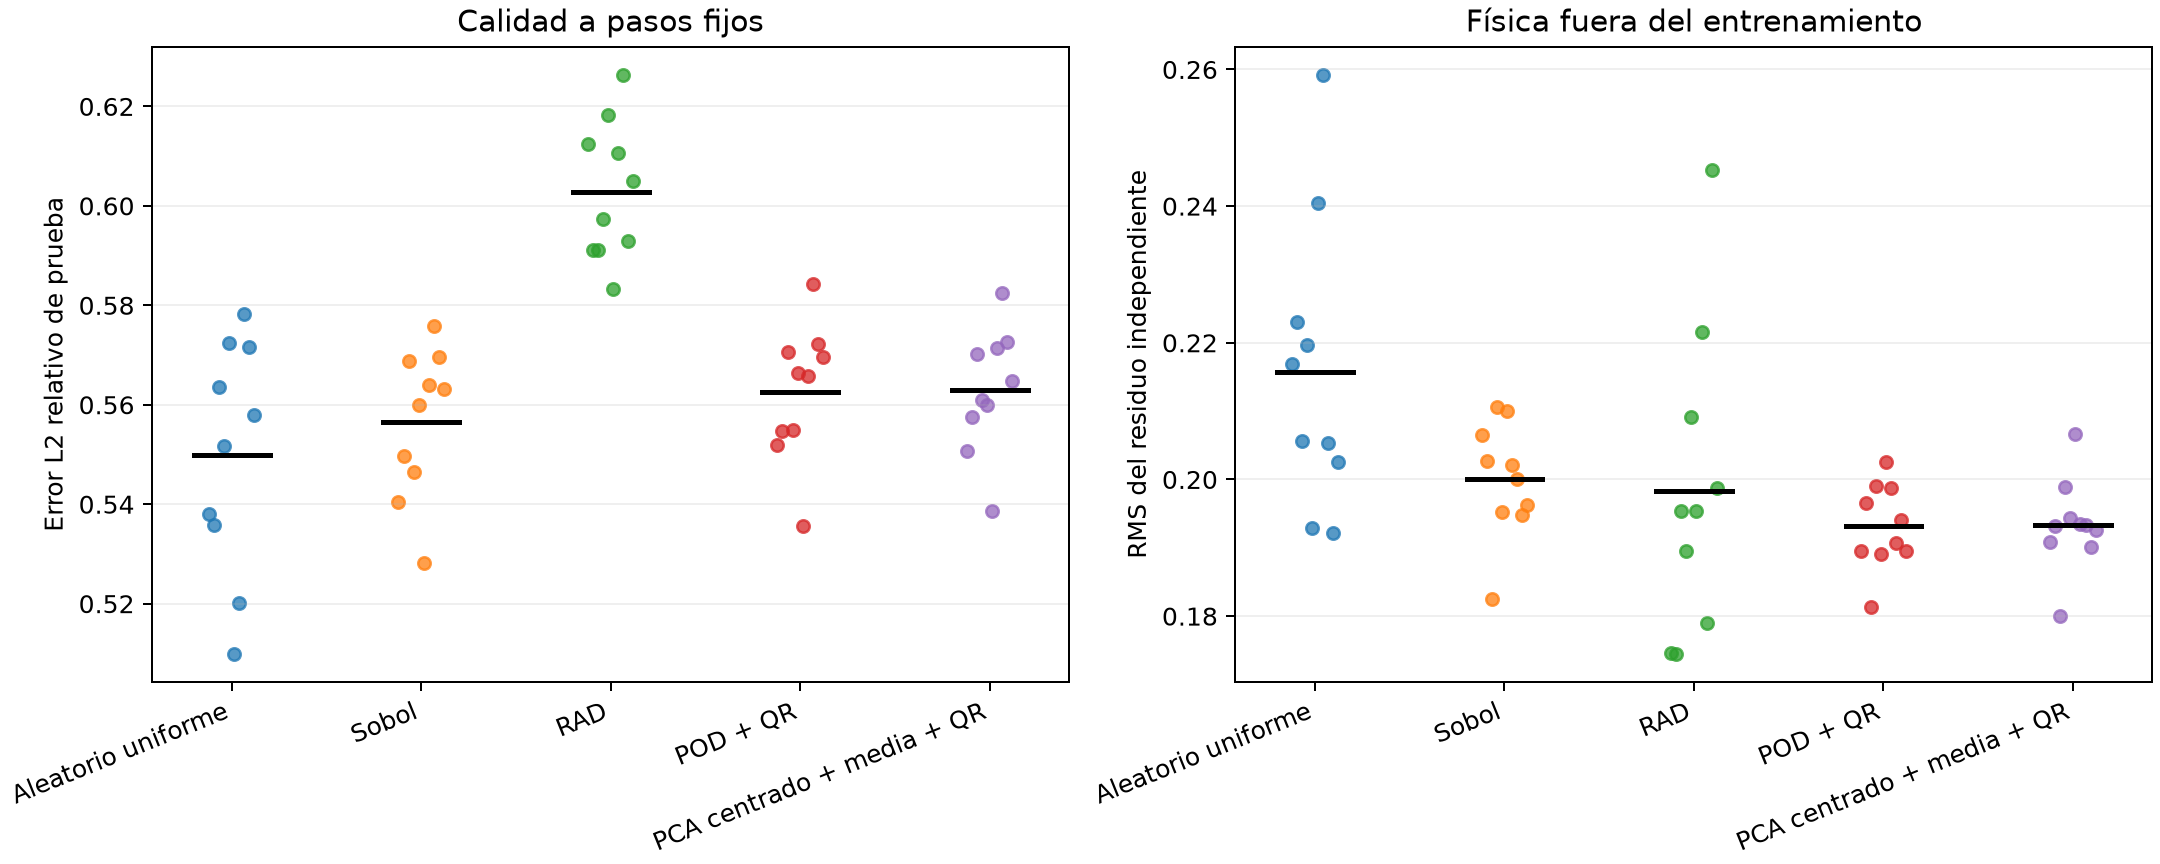

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/collocation_selection/residual_history_selection_confirmation_10_seeds_v1/confirmation_quality.png'), format='png', embed=True))


**Trayectorias de validación, promedio y DE**

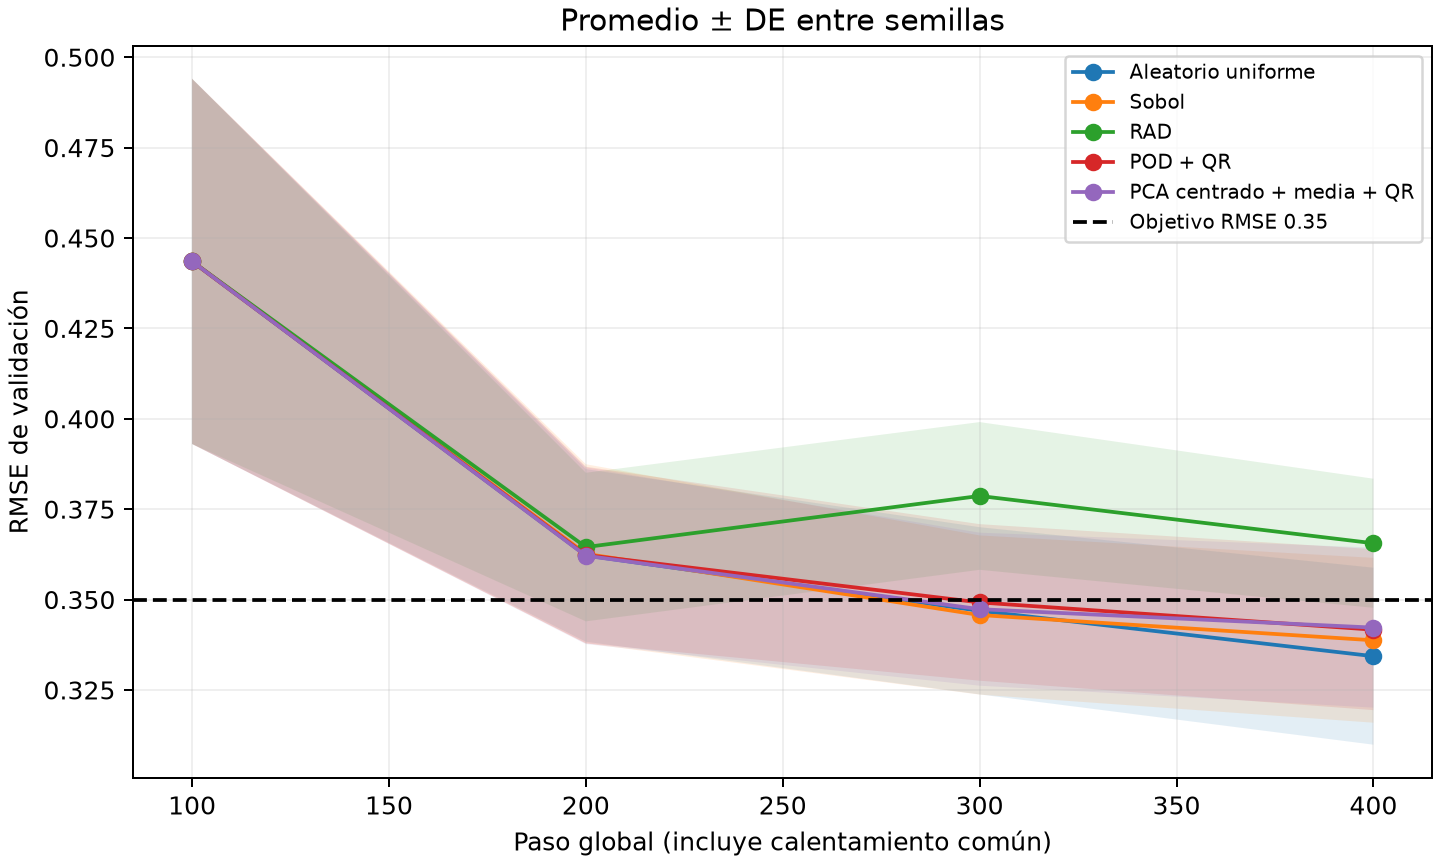

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/collocation_selection/residual_history_selection_confirmation_10_seeds_v1/confirmation_validation.png'), format='png', embed=True))


**Tasa de semillas que alcanzan el objetivo**

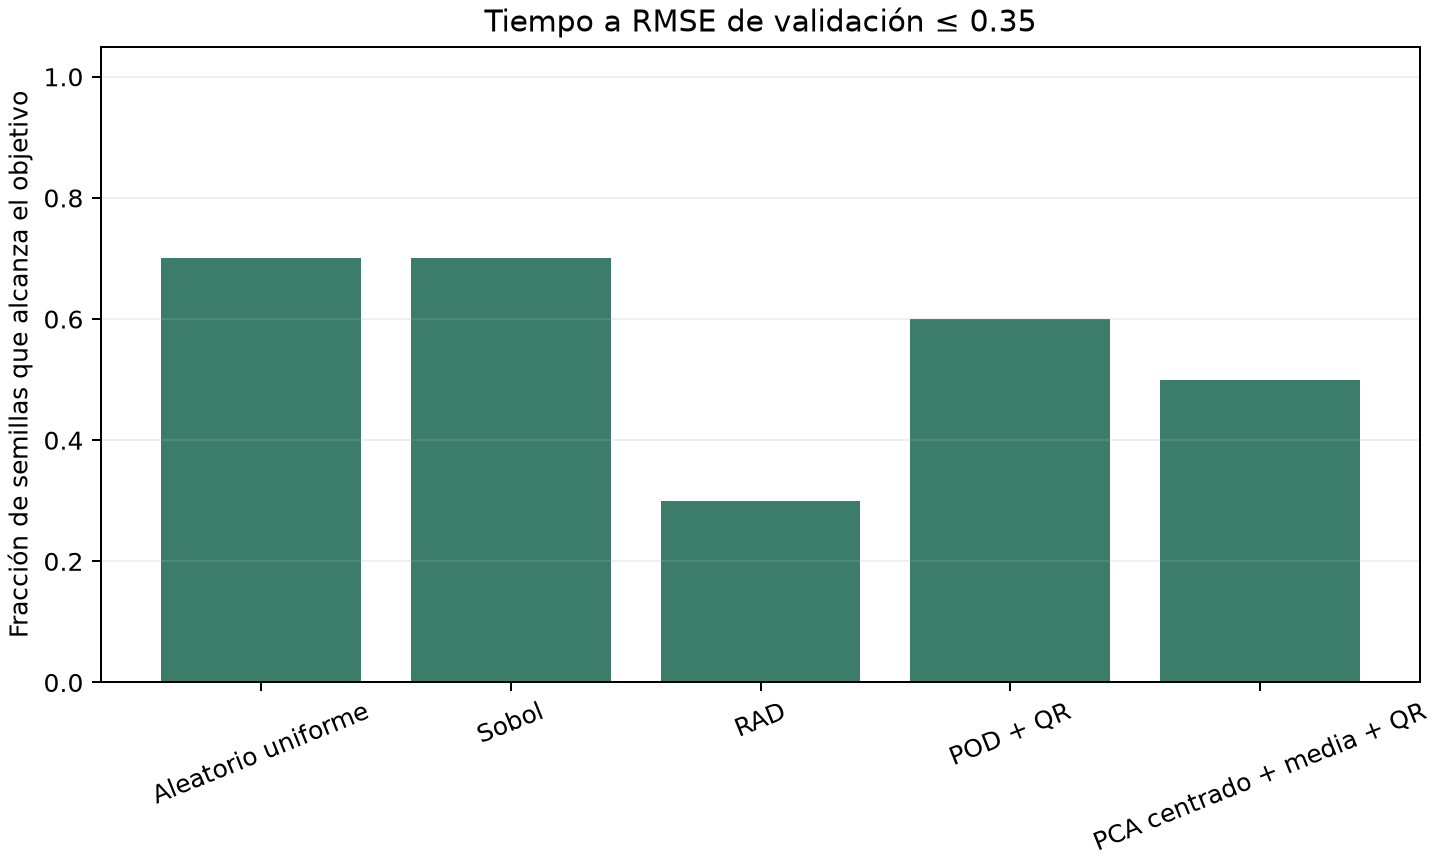

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/collocation_selection/residual_history_selection_confirmation_10_seeds_v1/target_hit_rate.png'), format='png', embed=True))


## Protocolo fijado

RAD muestrea sin reemplazo con probabilidad proporcional a (|r| − min|r| + 1e−8)². POD usa la historia sin centrar; PCA centra temporalmente y preserva su media como dirección adicional. Se retienen modos hasta el umbral de energía σ² y se eligen índices distintos mediante QR con pivoteo. La selección QR contribuyó inicialmente 3.0 (rango 2–4) puntos para POD y 4.1 (rango 4–5) para PCA con media (límite 32); los espacios del lote se completan con Sobol.

El conjunto de candidatos se mantiene fijo dentro de cada semilla; el conjunto independiente para residuo y los tiempos de prueba quedan fuera de la selección. Este estudio no implementa todavía poda adaptativa y sus conclusiones se limitan a este presupuesto y distribución de RAD.

In [ ]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / 'pyproject.toml').is_file() and ROOT != ROOT.parent: ROOT = ROOT.parent
OUT = ROOT / 'pca_collocation/results/burgers/collocation_selection/residual_history_selection_confirmation_10_seeds_v1'
summary = json.loads((OUT / 'summary.json').read_text(encoding='utf-8'))
metrics = pd.read_csv(OUT / 'metrics_by_seed.csv')
trace = pd.read_csv(OUT / 'validation_trajectories_by_seed.csv')
target_times = pd.read_csv(OUT / 'time_to_validation_target_by_seed.csv')
display(metrics.groupby('method')[['test_relative_l2','independent_residual_rms','pipeline_seconds_including_shared_setup']].agg(['mean','std']))
display(target_times.groupby('method').agg(reached=('reached','sum'), seeds=('seed','count')))